# 01 · EDA de la equidad: desigualdad social y de recursos

**Bloque exploratorio** (antes de elegir el tema), con los 33 países. Mide cuánta desigualdad hay en cada país y edición PISA, de dos tipos, y cómo se relaciona con el rendimiento en matemáticas:

* **Desigualdad social**: del conjunto de los hogares (Gini), de los alumnos (dispersión del `ESCS`) y entre centros (segregación).
* **Desigualdad de recursos entre centros**: cuánto mejor o peor dotados están los centros desfavorecidos que los favorecidos.

Los datos salen de las tablas maestras de `00_pipeline_multiedicion_PISA.ipynb` y, para el Gini, de la OCDE y el Banco Mundial. El presupuesto por alumno se analiza en `01_EDA_presupuestos.ipynb`. Además, guarda el `ESCS` medio (sección 5) y los recursos (sección 6) por centro y por país, y estudia su relación con la nota entre centros de un mismo país (sección 7).

| Variable | Qué mide | Nivel y fuente |
|---|---|---|
| `gini` | Desigualdad de la renta disponible de los hogares (0 = todos igual, 1 = uno concentra todo) | País y edición; OCDE (base de distribución de ingresos) y Banco Mundial |
| `pisa_escs_trend_desviacion_tipica` | Desviación típica de `ESCS_TREND` entre los alumnos del país | Alumnos; tablas maestras |
| `pisa_segregacion_social_entre_centros_pct` | % de la varianza de `ESCS_TREND` que es **entre centros** (más alto = centros más separados por nivel socioeconómico) | Alumnos y centros; tablas maestras |
| `pisa_brecha_alumnos_por_profesor`, `pisa_brecha_tamaño_clase`, `pisa_brecha_profesorado_certificado`, `pisa_brecha_escasez_material` y `pisa_brecha_escasez_personal` | **Brecha de recursos**: media del cuartil de centros más desfavorecido (por `ESCS_TREND` medio del centro) menos la del más favorecido, en alumnos por profesor, tamaño de clase, profesorado certificado, escasez de material y escasez de personal | Centros; tablas maestras (peso `W_SCHGRNRABWT`) |

## 0. Configuración

In [1]:
import sys, os
sys.path.append(os.path.abspath('../../'))   # para importar `src`

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.datos_externos import descargar_todo, cargar_oecd
from src.pisa_estadisticas import agregar_media_ponderada
from src.pisa_pipeline import leer_recursos_centros, rutas_datos_anuales
from src.presupuesto_pais_edicion import construir_tabla

RUTA_RAW = '../../data/raw'                    # tablas maestras: data/raw/datos_anuales/
RUTA_EXTERNOS = '../../data/raw/externos'
RUTA_INTERMEDIOS = '../../data/intermediate'
RUTA_REPORTS = '../../reports'
EDICIONES = [2012, 2015, 2018, 2022]


if not os.path.isdir(os.path.join(RUTA_RAW, 'datos_anuales')):
    raise FileNotFoundError('Faltan las tablas maestras en data/raw/datos_anuales: se generan con 00_pipeline_multiedicion_PISA.ipynb')

rutas = descargar_todo(RUTA_EXTERNOS)      # descarga lo que falte (salta los ficheros que ya existen)
tabla_pais_edicion = construir_tabla(RUTA_RAW, RUTA_EXTERNOS)

SOCIAL = ['gini', 'pisa_escs_trend_desviacion_tipica', 'pisa_segregacion_social_entre_centros_pct']
RECURSOS = ['pisa_brecha_alumnos_por_profesor', 'pisa_brecha_tamaño_clase', 'pisa_brecha_profesorado_certificado', 'pisa_brecha_escasez_material', 'pisa_brecha_escasez_personal']
print(f'{tabla_pais_edicion.shape[0]} filas (33 países × 4 ediciones)')

132 filas (33 países × 4 ediciones)


## 1. Gini

El **Gini** mide la desigualdad de la renta con un número de 0 (todos los hogares ingresan lo mismo) a 1 (uno solo concentra todo). Se usa el de la **renta disponible de los hogares** (después de impuestos y transferencias) de la OCDE, para la población total, con la metodología desde 2012 y la definición actual.

Para cada país y edición se toma la **observación más cercana al año de la edición (como mucho ±1 año)**. A igual distancia se prefiere la de la OCDE a la del Banco Mundial (que va de 0 a 100 y se divide entre 100) y, si aún empatan, el año anterior. `gini_fuente` y `gini_año` indican qué observación se usó. Las fuentes y sus enlaces están en `01_EDA_presupuestos.ipynb` (sección "Fuentes"); el Gini se guarda también en `presupuesto_pais_edicion.parquet`.

In [2]:
# Gini usado en cada edición: de qué fuente y de qué año es la observación
distancia_gini = (tabla_pais_edicion['gini_año'] - tabla_pais_edicion['edicion']).abs()
gini_cobertura = pd.DataFrame({
    'países con Gini': tabla_pais_edicion.groupby('edicion')['gini'].count(),
    'de la OCDE': tabla_pais_edicion[tabla_pais_edicion['gini_fuente'] == 'OCDE'].groupby('edicion').size(),
    'del Banco Mundial': tabla_pais_edicion[tabla_pais_edicion['gini_fuente'] == 'Banco Mundial'].groupby('edicion').size(),
    'del año exacto': tabla_pais_edicion[distancia_gini == 0].groupby('edicion').size(),
    'a ±1 año': tabla_pais_edicion[distancia_gini == 1].groupby('edicion').size(),
}).fillna(0).astype(int)
gini_cobertura['sin dato'] = [', '.join(sorted(tabla_pais_edicion[(tabla_pais_edicion['edicion'] == edicion_pisa) & tabla_pais_edicion['gini'].isna()]['pais'])) or '-' for edicion_pisa in gini_cobertura.index]
gini_cobertura

,países con Gini,de la OCDE,del Banco Mundial,del año exacto,a ±1 año,sin dato
edicion,,,,,,
2012,33,26,7,32,1,-
2015,33,29,4,31,2,-
2018,33,31,2,31,2,-
2022,31,30,1,29,2,"AUS, ISL"


In [3]:
# ¿Coinciden las dos fuentes? Países y años con dato en ambas
gini_ocde = cargar_oecd(rutas['gini_ocde']).assign(año=lambda datos: datos['año'].astype(int))
gini_banco_mundial = pd.read_csv(rutas['gini_banco_mundial']).dropna().assign(valor=lambda datos: datos['valor'] / 100)
ambas = gini_ocde.merge(gini_banco_mundial, on=['pais', 'año'], suffixes=('_ocde', '_bm'))
diferencia = ambas['valor_bm'] - ambas['valor_ocde']
print(f'{len(ambas)} pares país-año con dato en las dos fuentes: correlación = {ambas[["valor_ocde", "valor_bm"]].corr().iloc[0, 1]:.2f}; '
      f'el Banco Mundial es de media {diferencia.mean():+.3f} mayor (|diferencia| mediana {diferencia.abs().median():.3f}, percentil 90 {diferencia.abs().quantile(.9):.3f})')

444 pares país-año con dato en las dos fuentes: correlación = 0.96; el Banco Mundial es de media +0.013 mayor (|diferencia| mediana 0.017, percentil 90 0.028)


Las dos fuentes están muy correlacionadas, pero el Banco Mundial da valores algo más altos (las definiciones de renta y las encuestas de cada fuente no son idénticas). Por eso se prefiere siempre la OCDE y el Banco Mundial solo rellena huecos.

## 2. Cobertura

% de países sin dato en cada edición (de 33). Las brechas de recursos dependen de preguntas de centro que no existen en todas las ediciones.

In [4]:
porcentaje_nulos = tabla_pais_edicion.groupby('edicion')[SOCIAL + RECURSOS].agg(lambda columna: 100 * columna.isna().mean()).T
porcentaje_nulos['total'] = 100 * tabla_pais_edicion[SOCIAL + RECURSOS].isna().mean()
porcentaje_nulos.sort_values('total', ascending=False).round(0).astype(int)

edicion,2012,2015,2018,2022,total
pisa_brecha_escasez_personal,100,0,0,18,30
pisa_brecha_escasez_material,100,0,0,0,25
pisa_brecha_profesorado_certificado,6,6,9,12,8
pisa_brecha_alumnos_por_profesor,0,0,9,6,4
pisa_brecha_tamaño_clase,0,0,6,6,3
gini,0,0,0,6,2
pisa_segregacion_social_entre_centros_pct,0,0,0,0,0
pisa_escs_trend_desviacion_tipica,0,0,0,0,0


## 3. Desigualdad social y rendimiento

Relación de las tres medidas de desigualdad social con la nota media de matemáticas.

In [5]:
vars_equidad = SOCIAL + RECURSOS
datos_estandarizados = tabla_pais_edicion[['pais', 'edicion', 'pisa_matematicas'] + vars_equidad].copy()
datos_estandarizados[['pisa_matematicas'] + vars_equidad] = datos_estandarizados.groupby('edicion')[['pisa_matematicas'] + vars_equidad].transform(lambda columna: (columna - columna.mean()) / columna.std(ddof=0))

nombres_variables = {'gini': 'Gini de la renta', 'pisa_escs_trend_desviacion_tipica': 'dispersión del ESCS dentro del país', 'pisa_segregacion_social_entre_centros_pct': 'segregación social entre centros'}
colores = {2012: 'tab:blue', 2015: 'tab:orange', 2018: 'tab:green', 2022: 'tab:red'}
fig, ejes = plt.subplots(1, 3, figsize=(15, 4.4), sharey=True)
for ax, variable in zip(ejes, SOCIAL):
    datos_variable = datos_estandarizados[['pais', 'edicion', 'pisa_matematicas', variable]].dropna()
    ax.scatter(datos_variable[variable], datos_variable['pisa_matematicas'], c=datos_variable['edicion'].map(colores), s=20, alpha=0.75)
    for _, fila_espana in datos_variable[datos_variable['pais'] == 'ESP'].iterrows():
        ax.annotate(f"ESP {int(fila_espana['edicion']) % 100}", (fila_espana[variable], fila_espana['pisa_matematicas']), fontsize=7, xytext=(3, 3), textcoords='offset points')
    ax.set_title(f'{nombres_variables[variable]}\ncorrelación = {datos_variable[[variable, "pisa_matematicas"]].corr().iloc[0, 1]:.2f} ({len(datos_variable)} países-edición)', fontsize=10)
    ax.set_xlabel('desviaciones típicas respecto a la media de su edición')
ejes[0].set_ylabel('PISA matemáticas (desviaciones típicas)')
ejes[0].legend(handles=[plt.Line2D([], [], marker='o', ls='', color=color_edicion, label=edicion_pisa) for edicion_pisa, color_edicion in colores.items()], fontsize=8, loc='lower left')
plt.tight_layout()
fig.savefig(f'{RUTA_REPORTS}/01_desigualdad_y_rendimiento.png', dpi=300, bbox_inches='tight')
plt.close(fig)  

Cada punto es un país y una edición. Las variables se estandarizan **dentro de cada edición** (se resta la media de la edición y se divide entre su desviación típica) para no mezclar escalas ni la caída general de 2018 a 2022. España aparece rotulada. Cada correlación es la **r de Pearson** (entre −1 y 1: cuánto se mueven juntas dos variables en línea recta; no implica causa).

<img src="../../reports/01_desigualdad_y_rendimiento.png" alt="Desigualdad social y rendimiento" width="100%">

**Observaciones:**

* **Dispersión del ESCS dentro del país** (r = −0,70, 132 países-edición): es la relación negativa más clara. Cuanto mayores son las diferencias socioeconómicas entre las familias del país, menor es su nota media.
* **Gini de la renta** (r = −0,59, 130 países-edición): correlación negativa moderada. Los países con más desigualdad de ingresos tienden a obtener peores puntuaciones.
* **Segregación social entre centros** (r = −0,57, 132 países-edición): correlación negativa moderada. Donde el alumnado está más separado en centros según su nivel socioeconómico, la nota media del país es más baja.

### 3.1 Cuánto se solapan

Correlación entre las tres medidas sociales (estandarizadas por edición). Si fuera muy alta, serían casi la misma información.

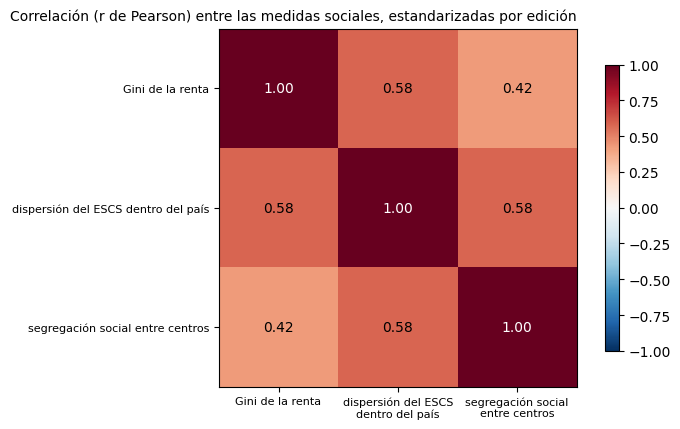

In [6]:
etiquetas = [nombres_variables[variable] for variable in SOCIAL]
correlacion_entre_medidas_sociales = datos_estandarizados[SOCIAL].corr()
fig, ax = plt.subplots(figsize=(7, 4.4))
mapa_calor = ax.imshow(correlacion_entre_medidas_sociales, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(3), [etiqueta.replace(' dentro del', '\ndentro del').replace(' entre', '\nentre') for etiqueta in etiquetas], fontsize=8)
ax.set_yticks(range(3), etiquetas, fontsize=8)
for fila in range(3):
    for columna in range(3):
        ax.text(columna, fila, f'{correlacion_entre_medidas_sociales.iloc[fila, columna]:.2f}', ha='center', va='center', color='white' if abs(correlacion_entre_medidas_sociales.iloc[fila, columna]) > 0.6 else 'black')
fig.colorbar(mapa_calor, ax=ax, shrink=0.8)
ax.set_title('Correlación (r de Pearson) entre las medidas sociales, estandarizadas por edición', fontsize=10, loc='right')
plt.tight_layout()
fig.savefig(f'{RUTA_REPORTS}/01_correlacion_medidas_sociales.png', dpi=300, bbox_inches='tight')
plt.show() 

Las tres medidas correlacionan entre 0,42 (Gini y segregación) y 0,58 (dispersión del `ESCS` con cada una de las otras dos): están relacionadas, pero cada una aporta información propia.

## 4. Desigualdad de recursos entre centros


La **brecha** de cada recurso es la resta de la media del cuartil de centros más desfavorecido con la del más favorecido (según el `ESCS` medio de sus alumnos).


$$ \text{Brecha} = \text{Media}_{\text{Desfavorecido}} - \text{Media}_{\text{Favorecido}} $$


In [7]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 6), sharey=False)
for ax, (columna_brecha, titulo) in zip(ejes, [('pisa_brecha_alumnos_por_profesor', 'alumnos por profesor'), ('pisa_brecha_tamaño_clase', 'tamaño de clase'),
                                     ('pisa_brecha_profesorado_certificado', 'profesorado certificado (pp)')]):
    brecha_2022 = tabla_pais_edicion[tabla_pais_edicion['edicion'] == 2022].dropna(subset=[columna_brecha]).set_index('pais')[columna_brecha].sort_values()
    brecha_2022.plot.barh(ax=ax, color=['tab:green' if valor_brecha < 0 else 'tab:red' for valor_brecha in brecha_2022] if columna_brecha != 'pisa_brecha_profesorado_certificado'
                else ['tab:red' if valor_brecha < 0 else 'tab:green' for valor_brecha in brecha_2022])
    ax.axvline(0, color='black', lw=0.8)
    ax.set_title(titulo, fontsize=10)
    ax.set_ylabel('')
plt.suptitle('Brecha de recursos 2022: centros desfavorecidos menos favorecidos (verde = mejor dotados los desfavorecidos)', fontsize=11)
plt.tight_layout()
fig.savefig(f'{RUTA_REPORTS}/01_brecha_recursos_entre_centros.png', dpi=300, bbox_inches='tight')
plt.close(fig)


Para interpretar los resultados negativos hay que atender al tipo de variable que se está analizando:

* En variables de carga (alumnos por profesor, tamaño de clase o escasez): Un valor negativo es mejor, ya que indica que los centros desfavorecidos tienen menos saturación o menos faltas materiales.
* En variables de calidad (profesorado certificado): Un valor negativo es peor, ya que indica que los centros desfavorecidos cuentan con un menor porcentaje de docentes cualificados.


Para facilitar la lectura, los valores se muestran en términos de equidad: el color <span style="color: #2e7d32; font-weight: bold;">verde</span> indica ventaja para los centros desfavorecidos y el <span style="color: #c62828; font-weight: bold;">rojo</span> indica desventaja.


<img src="../../reports/01_brecha_recursos_entre_centros.png" alt="Brecha de recursos entre centros en 2022" width="70%">

In [8]:
# Patrones de 2022 que se comentan en los hallazgos
brechas_2022 = tabla_pais_edicion[tabla_pais_edicion['edicion'] == 2022].set_index('pais')
for columna, recurso in (('pisa_brecha_alumnos_por_profesor', 'alumnos por profesor'), ('pisa_brecha_tamaño_clase', 'tamaño de clase')):
    valores = brechas_2022[columna].dropna()
    print(f'**{recurso}:\n  -los centros desfavorecidos están mejor dotados (brecha negativa) en {(valores < 0).sum()} de {len(valores)} países;\n  -brecha positiva en: {", ".join(valores[valores > 0].index)}\n')
certificados = brechas_2022['pisa_brecha_profesorado_certificado'].dropna().sort_values()
print('**Profesorado certificado: \n    -brecha en puntos porcentuales (4 menores y 4 mayores):', certificados.head(4).round(0).to_dict(), certificados.tail(4).round(0).to_dict())

**alumnos por profesor:
  -los centros desfavorecidos están mejor dotados (brecha negativa) en 22 de 31 países;
  -brecha positiva en: CHE, CZE, DNK, FRA, GBR, MEX, PRT, TUR, USA

**tamaño de clase:
  -los centros desfavorecidos están mejor dotados (brecha negativa) en 29 de 31 países;
  -brecha positiva en: GBR, POL

**Profesorado certificado: 
    -brecha en puntos porcentuales (4 menores y 4 mayores): {'CAN': -21.0, 'ISR': -20.0, 'NLD': -15.0, 'AUT': -11.0} {'MEX': 20.0, 'USA': 25.0, 'FRA': 27.0, 'TUR': 29.0}


### 4.1 Relación con el rendimiento

In [9]:
etiquetas_vars = {**nombres_variables, 'pisa_brecha_alumnos_por_profesor': 'brecha alumnos por profesor', 'pisa_brecha_tamaño_clase': 'brecha tamaño de clase',
                  'pisa_brecha_profesorado_certificado': 'brecha profesorado certificado', 'pisa_brecha_escasez_material': 'brecha escasez de material (desde 2015)',
                  'pisa_brecha_escasez_personal': 'brecha escasez de personal (desde 2015)'}
correlacion_con_matematicas = pd.DataFrame({variable: {'r': datos_estandarizados[['pisa_matematicas', variable]].dropna().corr().iloc[0, 1], 'n': len(datos_estandarizados[['pisa_matematicas', variable]].dropna())} for variable in vars_equidad}).T
correlacion_con_matematicas = correlacion_con_matematicas.sort_values('r', key=abs)
fig, ax = plt.subplots(figsize=(9, 4.2))
barras = ax.barh([etiquetas_vars[variable] for variable in correlacion_con_matematicas.index], correlacion_con_matematicas['r'],
                 color=['tab:blue' if variable in SOCIAL else 'tab:orange' for variable in correlacion_con_matematicas.index])
ax.bar_label(barras, labels=[f'{correlacion:.2f}  (n={int(n_observaciones)})' for correlacion, n_observaciones in zip(correlacion_con_matematicas['r'], correlacion_con_matematicas['n'])], padding=3, fontsize=8)
ax.axvline(0, color='black', lw=0.8)
ax.set_xlim(-0.9, 0.2)
ax.set_xlabel('correlación (r de Pearson) con PISA matemáticas\n(variables estandarizadas por edición)')
ax.set_title('Desigualdad y rendimiento (azul: social; naranja: recursos entre centros)', fontsize=10)
fig.savefig(f'{RUTA_REPORTS}/01_ranking_correlacion_variables_sociales_recursos.png', dpi=300, bbox_inches='tight')
plt.close(fig)

<img src="../../reports/01_ranking_correlacion_variables_sociales_recursos.png" alt="Correlación de las medidas de desigualdad con la nota de matemáticas" width="80%">

### 4.2 España y estabilidad entre ediciones

Posición de España en 2022 y cuánto se parecen los países entre ediciones, para situar los resultados anteriores.

In [10]:
medidas_espana = ['gini', 'pisa_escs_trend_desviacion_tipica', 'pisa_segregacion_social_entre_centros_pct', 'pisa_brecha_alumnos_por_profesor']
medidas_2022 = tabla_pais_edicion[tabla_pais_edicion['edicion'] == 2022].set_index('pais')[medidas_espana]
display(pd.DataFrame({'España': medidas_2022.loc['ESP'], 'mediana': medidas_2022.median(), 'puesto de mayor a menor': medidas_2022.rank(ascending=False).loc['ESP'].astype(int),
                      'países con dato': medidas_2022.count()}).round(3))

# Estabilidad: correlación entre países de los valores de 2015 y de 2022
estabilidad = pd.Series({variable: tabla_pais_edicion.pivot(index='pais', columns='edicion', values=variable)[[2015, 2022]].dropna().corr().iloc[0, 1] for variable in SOCIAL + RECURSOS},
                        name='correlación entre países 2015-2022')
estabilidad.round(2)

,España,mediana,puesto de mayor a menor,países con dato
gini,0.316,0.309,15,31
pisa_escs_trend_desviacion_tipica,1.009,0.920,5,33
pisa_segregacion_social_entre_centros_pct,23.288,26.106,23,33
pisa_brecha_alumnos_por_profesor,-4.536,-1.247,30,31


gini                                         0.94
pisa_escs_trend_desviacion_tipica            0.88
pisa_segregacion_social_entre_centros_pct    0.85
pisa_brecha_alumnos_por_profesor             0.71
pisa_brecha_tamaño_clase                     0.72
pisa_brecha_profesorado_certificado          0.31
pisa_brecha_escasez_material                 0.68
pisa_brecha_escasez_personal                 0.44
Name: correlación entre países 2015-2022, dtype: float64

## 5. ESCS medio por centro y por país

`ESCS_TREND` medio de los alumnos de cada centro y de cada país, en cada edición, ponderado con `W_FSTUWT` (`agregar_media_ponderada` de `src/pisa_estadisticas.py`; los alumnos sin `ESCS` no cuentan). El centro se identifica con `CNT` + `CNTSCHID`, porque en 2012 `CNTSCHID` se repite entre países.

Se guardan en `data/intermediate/escs_anual/` (`pisa_escs_centro_anual.parquet` y `pisa_escs_pais_anual.parquet`) El `ESCS` medio del centro se usa en la comprobación que lo pone en lugar de la composición social del centro (`src/tabla_alumno.py`).

In [11]:
# ESCS_TREND medio por centro y por país, en cada edición
ruta_escs = os.path.join(RUTA_INTERMEDIOS, 'escs_anual')
os.makedirs(ruta_escs, exist_ok=True)
escs_por_nivel = {'pais': [], 'centro': []}
for edicion in EDICIONES:
    ruta_estudiantes, _ = rutas_datos_anuales(RUTA_RAW, edicion)
    alumnos = pd.read_parquet(ruta_estudiantes, columns=['CNT', 'CNTSCHID', 'W_FSTUWT', 'ESCS_TREND'])
    for nivel, nombre in (('pais', 'escs_media_pais'), ('centro', 'escs_centro')):
        escs_nivel = agregar_media_ponderada(alumnos.rename(columns={'ESCS_TREND': nombre}), [nombre], claves=nivel)
        escs_por_nivel[nivel].append(escs_nivel.assign(year=edicion))

df_escs_pais = pd.concat(escs_por_nivel['pais'], ignore_index=True).sort_values(['year', 'CNT'], ascending=False, ignore_index=True)
df_escs_centro = pd.concat(escs_por_nivel['centro'], ignore_index=True).sort_values(['year', 'CNT', 'CNTSCHID'], ascending=False, ignore_index=True)
df_escs_pais.to_parquet(os.path.join(ruta_escs, 'pisa_escs_pais_anual.parquet'), index=False)
df_escs_centro.to_parquet(os.path.join(ruta_escs, 'pisa_escs_centro_anual.parquet'), index=False)
print(f'ESCS por país: {df_escs_pais.shape} | por centro: {df_escs_centro.shape} -> {ruta_escs}')
print('centros sin ningún alumno con ESCS, por edición:', df_escs_centro['escs_centro'].isna().groupby(df_escs_centro['year']).sum().to_dict())

# Comprobación: el ESCS por país coincide con el de la tabla país-edición de las secciones anteriores
comparacion = df_escs_pais.merge(tabla_pais_edicion[['pais', 'edicion', 'pisa_escs_trend_media']], left_on=['CNT', 'year'], right_on=['pais', 'edicion'])
print(f"diferencia máxima con `pisa_escs_trend_media`: {(comparacion['escs_media_pais'] - comparacion['pisa_escs_trend_media']).abs().max():.1e}")
df_escs_centro.groupby('year')['escs_centro'].describe().round(2)

ESCS por país: (132, 3) | por centro: (41298, 4) -> ../../data/intermediate\escs_anual
centros sin ningún alumno con ESCS, por edición: {2012: 7, 2015: 22, 2018: 57, 2022: 46}
diferencia máxima con `pisa_escs_trend_media`: 0.0e+00


,count,mean,std,min,25%,50%,75%,max
year,,,,,,,,
2012,11718.0,-0.38,0.83,-5.56,-0.74,-0.24,0.18,1.42
2015,9054.0,-0.18,0.68,-4.08,-0.53,-0.11,0.29,1.96
2018,10309.0,-0.11,0.64,-3.54,-0.48,-0.06,0.33,1.50
2022,10085.0,0.00,0.62,-3.73,-0.34,0.07,0.44,1.96


## 6. Recursos por centro y por país

Recursos de cada centro del cuestionario de centro, con nombres comunes a todas las ediciones (`leer_recursos_centros` de `src/pisa_pipeline.py`): alumnos por profesor, tamaño de clase y de centro, titularidad (`centro_publico`: 1 si `SCHLTYPE` = 3), financiación por origen, profesorado certificado y con máster (en %), ordenadores por alumno, autonomía sobre recursos y escasez de material y de personal. Algunas variables no existen en todas las ediciones: el máster solo en 2022, la escasez desde 2015, y la autonomía no está en 2018 (y no es comparable entre ediciones).

La tabla por país es la de las secciones anteriores: la media de cada recurso ponderada con el peso del centro (`W_SCHGRNRABWT`) y las brechas entre los centros más desfavorecidos y los más favorecidos.

Se guardan en `data/intermediate/recursos_anual/` (`pisa_recursos_centro_anual.parquet` y `pisa_recursos_pais_anual.parquet`).

In [12]:
# Recursos de cada centro (nombres comunes a todas las ediciones) y su resumen por país, en cada edición
ruta_recursos = os.path.join(RUTA_INTERMEDIOS, 'recursos_anual')
os.makedirs(ruta_recursos, exist_ok=True)
df_recursos_centro = pd.concat([leer_recursos_centros(RUTA_RAW, edicion).assign(year=edicion) for edicion in EDICIONES], ignore_index=True)
df_recursos_centro = df_recursos_centro.sort_values(['year', 'CNT', 'CNTSCHID'], ascending=False, ignore_index=True)

columnas_recursos_pais = ['pisa_numero_centros', 'pisa_alumnos_por_profesor', 'pisa_tamaño_clase', 'pisa_tamaño_centro', 'pisa_centros_publicos_pct',
                          'pisa_financiacion_centro_gobierno_pct', 'pisa_financiacion_centro_cuotas_pct', 'pisa_financiacion_centro_donaciones_pct',
                          'pisa_financiacion_centro_otras_pct', 'pisa_profesores_certificados_pct', 'pisa_profesores_master_pct',
                          'pisa_ordenadores_por_alumno', 'pisa_autonomia_recursos', 'pisa_escasez_material_educativo', 'pisa_escasez_personal'] + RECURSOS
df_recursos_pais = (tabla_pais_edicion[['pais', 'edicion'] + columnas_recursos_pais].rename(columns={'pais': 'CNT', 'edicion': 'year'})
                    .sort_values(['year', 'CNT'], ascending=False, ignore_index=True))

df_recursos_centro.to_parquet(os.path.join(ruta_recursos, 'pisa_recursos_centro_anual.parquet'), index=False)
df_recursos_pais.to_parquet(os.path.join(ruta_recursos, 'pisa_recursos_pais_anual.parquet'), index=False)
print(f'recursos por centro: {df_recursos_centro.shape} | por país: {df_recursos_pais.shape} -> {ruta_recursos}')

# % de centros sin dato en cada recurso y edición
variables_recursos_centro = [columna for columna in df_recursos_centro.columns if columna not in ('CNT', 'CNTSCHID', 'W_SCHGRNRABWT', 'year')]
df_recursos_centro[variables_recursos_centro].isna().groupby(df_recursos_centro['year']).mean().mul(100).round(0).T

recursos por centro: (41298, 18) | por país: (132, 22) -> ../../data/intermediate\recursos_anual


year,2012,2015,2018,2022
centro_publico,5.0,15.0,12.0,13.0
alumnos_por_profesor,11.0,14.0,23.0,24.0
tamaño_clase,5.0,10.0,16.0,21.0
tamaño_centro,7.0,15.0,22.0,20.0
financiacion_gobierno_pct,14.0,22.0,18.0,18.0
financiacion_cuotas_pct,16.0,34.0,35.0,19.0
financiacion_donaciones_pct,20.0,37.0,39.0,20.0
financiacion_otras_pct,21.0,46.0,41.0,20.0
profesores_certificados_pct,18.0,22.0,22.0,26.0
profesores_master_pct,100.0,100.0,100.0,22.0


## 7. ESCS, recursos y nota por centro, dentro de cada país

Hasta aquí la desigualdad se ha estudiado entre países. Aquí se mira también entre centros de un mismo país: la nota media de matemáticas de cada centro (`01_EDA_notas_asignatura`) frente a su `ESCS` medio y sus recursos (secciones 5 y 6). Cada variable se centra restándole la media de su país-edición, de modo que las correlaciones comparan centros del mismo país y edición, no países entre sí. Cada centro pesa igual (no se pondera), y en los centros con pocos alumnos evaluados la nota media tiene más ruido.

Para cada variable, tres correlaciones (r de Pearson):

* **con la nota del centro**;
* **con la nota, descontando el `ESCS` del centro**: la correlación entre lo que queda de la variable y de la nota después de quitarles lo que explica el `ESCS` medio. Si un recurso solo se asocia a la nota porque lo tienen los centros más favorecidos, aquí desaparece;
* **con el `ESCS` del centro**: si los centros más favorecidos tienen más o menos de ese recurso.

No entran el profesorado con máster (solo existe en 2022) ni la autonomía (no es comparable entre ediciones).

centros con dato en cada variable: {'ESCS medio del centro': 41166, 'alumnos por profesor': 33870, 'tamaño de clase': 35992, 'tamaño del centro': 34686, 'centro público': 36700, '% financiado por el gobierno': 34008, '% de profesorado certificado': 32100, 'ordenadores por alumno': 35442, 'escasez de material (desde 2015)': 26834, 'escasez de personal (desde 2015)': 24969}


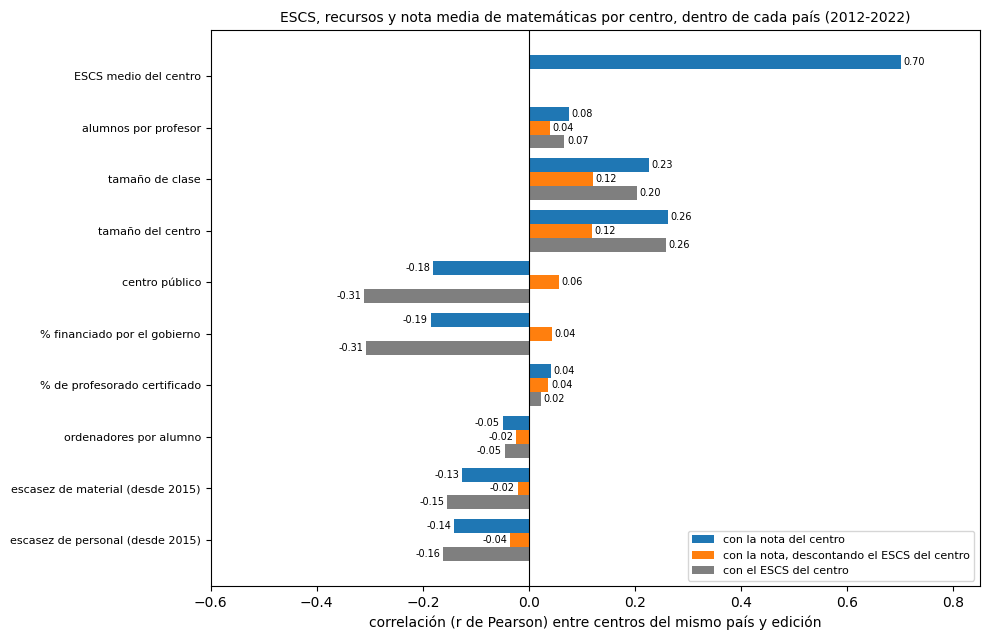

In [13]:
# Nota, ESCS y recursos de cada centro, centrados en la media de su país-edición (relación dentro de cada país)
notas_centro = pd.read_parquet(os.path.join(RUTA_INTERMEDIOS, 'medias_asignaturas_anual', 'pisa_medias_asignaturas_centro_anual.parquet'),
                               columns=['CNT', 'CNTSCHID', 'year', 'media_math_centro'])
centros = (notas_centro.merge(df_escs_centro, on=['CNT', 'CNTSCHID', 'year'], validate='one_to_one')
                       .merge(df_recursos_centro, on=['CNT', 'CNTSCHID', 'year'], validate='one_to_one'))
variables_centro = {'escs_centro': 'ESCS medio del centro', 'alumnos_por_profesor': 'alumnos por profesor', 'tamaño_clase': 'tamaño de clase',
                    'tamaño_centro': 'tamaño del centro', 'centro_publico': 'centro público', 'financiacion_gobierno_pct': '% financiado por el gobierno',
                    'profesores_certificados_pct': '% de profesorado certificado', 'ordenadores_por_alumno': 'ordenadores por alumno',
                    'escasez_material_educativo': 'escasez de material (desde 2015)', 'escasez_personal': 'escasez de personal (desde 2015)'}


def centrar_en_pais_edicion(tabla, columnas):
    return tabla[columnas] - tabla.groupby(['CNT', 'year'])[columnas].transform('mean')


def residuo_sobre(variable, control):
    pendiente = (variable * control).sum() / (control ** 2).sum()   # ya están centradas: regresión sin constante
    return variable - pendiente * control


filas = []
for variable, etiqueta in variables_centro.items():
    columnas = list(dict.fromkeys(['media_math_centro', 'escs_centro', variable]))
    datos_variable = centros.dropna(subset=columnas)
    centradas = centrar_en_pais_edicion(datos_variable, columnas)
    fila = {'variable': etiqueta, 'centros': len(datos_variable),
            'con la nota del centro': centradas[variable].corr(centradas['media_math_centro'])}
    if variable != 'escs_centro':
        fila['con la nota, descontando el ESCS del centro'] = residuo_sobre(centradas[variable], centradas['escs_centro']).corr(
            residuo_sobre(centradas['media_math_centro'], centradas['escs_centro']))
        fila['con el ESCS del centro'] = centradas[variable].corr(centradas['escs_centro'])
    filas.append(fila)
correlaciones_centro = pd.DataFrame(filas).set_index('variable')
print('centros con dato en cada variable:', correlaciones_centro['centros'].to_dict())

fig, ax = plt.subplots(figsize=(10, 6.5))
series = ['con la nota del centro', 'con la nota, descontando el ESCS del centro', 'con el ESCS del centro']
orden = correlaciones_centro.index[::-1]
alto_barra = 0.27
for posicion, (serie, color) in enumerate(zip(series, ['tab:blue', 'tab:orange', 'tab:gray'])):
    valores = correlaciones_centro.loc[orden, serie]
    barras = ax.barh(np.arange(len(orden)) + (1 - posicion) * alto_barra, valores, height=alto_barra, color=color, label=serie)
    ax.bar_label(barras, labels=['' if pd.isna(valor) else f'{valor:.2f}' for valor in valores], padding=2, fontsize=7)
ax.set_yticks(np.arange(len(orden)), orden, fontsize=8)
ax.axvline(0, color='black', lw=0.8)
ax.set_xlim(-0.6, 0.85)
ax.set_xlabel('correlación (r de Pearson) entre centros del mismo país y edición')
ax.set_title('ESCS, recursos y nota media de matemáticas por centro, dentro de cada país (2012-2022)', fontsize=10)
ax.legend(fontsize=8, loc='lower right')
plt.tight_layout()
fig.savefig(f'{RUTA_REPORTS}/01_recursos_centro_y_nota.png', dpi=300, bbox_inches='tight')
plt.show()

**Qué se ve.**

* **El `ESCS` del centro es, con diferencia, lo que más se relaciona con su nota**: r = 0,70 entre centros del mismo país y edición.
* **Los recursos del centro se relacionan poco con la nota, y casi todo pasa por el `ESCS`.** Al descontarlo, las correlaciones se quedan entre −0,04 y 0,12. Los centros públicos y los más financiados por el gobierno sacan peor nota (−0,18 y −0,19), pero porque atienden a alumnos menos favorecidos (−0,31 con el `ESCS` del centro): con el mismo `ESCS`, su relación con la nota pasa a ser ligeramente positiva (0,06 y 0,04). La escasez de material y de personal se asocia a peor nota (−0,13 y −0,14), pero también por la composición social (−0,02 y −0,04 al descontar el `ESCS`).
* **Las clases y los centros más grandes sacan mejor nota** (0,23 y 0,26), sobre todo porque son más favorecidos (0,20 y 0,26 con el `ESCS`). Descontado el `ESCS` queda una relación pequeña (0,12 en los dos), que probablemente recoge otras diferencias entre centros (zona urbana, tipo de enseñanza) y no que las clases grandes mejoren la nota.

Para el modelo: al comparar alumnos de centros distintos, la composición social del centro tiene que entrar como control, porque sin ella cualquier variable del centro recogería a qué alumnos atiende. El modelo usa la composición social del centro sin las posesiones del hogar (`composicion_social_centro`, `01_EDA_variables_modelo`).

## Hallazgos

* **La desigualdad social se asocia con peor rendimiento** (dentro de cada edición, 33 países): dispersión del `ESCS` r = −0,70, Gini −0,59 y segregación entre centros −0,57. Entre sí correlacionan 0,42-0,58: son medidas distintas pero solapadas, no tres pruebas independientes.
* **Las brechas de recursos también**: escasez de material (−0,55; solo desde 2015), alumnos por profesor (−0,47) y escasez de personal (−0,41). Cuanto peor dotados están los centros desfavorecidos respecto a los favorecidos, menos puntos obtiene el país. Tamaño de clase (−0,31) y profesorado certificado (−0,24) son más débiles; en certificados el signo es contrario al esperado (más profesorado certificado en los desfavorecidos, peor media), así que no es concluyente.
* **Los centros desfavorecidos no siempre están peor dotados**: en 2022, en 22 de 31 países tienen menos alumnos por profesor y en 29 de 31 clases más pequeñas; lo contrario ocurre en 9 países en alumnos por profesor (Suiza, Chequia, Dinamarca, Francia, Reino Unido, México, Portugal, Turquía y Estados Unidos) y en 2 en tamaño de clase (Reino Unido y Polonia). Puede reflejar centros rurales pequeños y no solo compensación. En profesorado certificado faltan en los desfavorecidos de Canadá, Israel, Países Bajos y Austria (−11 a −21 puntos porcentuales) y sobran en Turquía, Francia, Estados Unidos y México (+20 a +29).
* **España en 2022**: Gini 0,316 (puesto 15 de 31, cerca de la mediana 0,309), dispersión del `ESCS` 1,01 (puesto 5 de 33: de las más altas), segregación 23,3 % (puesto 23 de 33: por debajo de la mediana, 26,1 %) y brecha de alumnos por profesor de −4,5 (puesto 30 de 31: de los países donde los centros desfavorecidos están mejor dotados).

* **Entre centros de un mismo país** (sección 7), el `ESCS` del centro se relaciona mucho con su nota (r = 0,70) y los recursos, poco: descontado el `ESCS`, sus correlaciones con la nota quedan entre −0,04 y 0,12. Los centros públicos y con escasez de recursos sacan peor nota porque atienden a alumnos menos favorecidos, no por sus recursos.

**Qué se lleva al tema del TFM**: la desigualdad y las brechas de recursos son características de cada país que cambian poco entre ediciones, así que con 33 países no permiten estudiar cómo cambia la nota entre 2012 y 2022. El TFM compara alumnos dentro de cada país, y el centro entra a través de su perfil y de su composición social.

**Cautelas**: son 33 países y las medidas sociales cambian poco entre ediciones (correlación entre países 2015-2022 de 0,85 a 0,94), así que las 4 ediciones aportan poco más que 33 observaciones independientes; las brechas de recursos son menos estables (0,31 a 0,72); las asociaciones no son causales y mezclan el nivel de renta y de desarrollo del país; las brechas de escasez de material y de personal solo existen desde 2015; el Gini no tiene dato de Australia e Islandia en 2022.

## Otros indicadores del sistema escolar (no analizados)

`construir_tabla` calcula más variables de contexto que **no** se analizan aquí, porque no forman un tema con el de equidad o aportan poco más que las anteriores: tiempo de aprendizaje en clase (`pisa_minutos_semanales_*`), autonomía sobre recursos (`pisa_autonomia_recursos`, sin dato en 2018 y no comparable entre ediciones), recursos de los centros (`pisa_alumnos_por_profesor`, `pisa_tamaño_clase`, `pisa_tamaño_centro`, `pisa_ordenadores_por_alumno`, `pisa_escasez_material_educativo`, `pisa_escasez_personal`), profesorado (`pisa_profesores_certificados_pct`, `pisa_profesores_master_pct`, `docentes_50_o_mas_años_pct`, `docentes_menos_de_30_años_pct`, `horas_docencia_anuales_secundaria_primera_etapa`), acceso y trayectoria (`escolarizacion_*_años_pct`, `repeticion_pct_secundaria_primera_etapa`) y titularidad (`pisa_centros_publicos_pct`). Están disponibles en `tabla_pais_edicion` si hicieran falta.